In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")
plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
url_hr = "https://raw.githubusercontent.com/OmerFarukMerey/IBM-HR-Analytics-Employee-Attrition-Performance/master/HR-Employee-Attrition.csv"
df_hr = pd.read_csv(url_hr)

# Drop non-informative constant columns
drop_cols = ['EmployeeCount', 'Over18', 'StandardHours']
df_hr.drop(columns=[c for c in drop_cols if c in df_hr.columns], inplace=True)

# Binary target variable
df_hr['Attrition_Num'] = df_hr['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

print("Dataset Shape:", df_hr.shape)
print("Missing Values:", df_hr.isnull().sum().sum())
print("Duplicate Rows:", df_hr.duplicated().sum())

Dataset Shape: (1470, 33)
Missing Values: 0
Duplicate Rows: 0


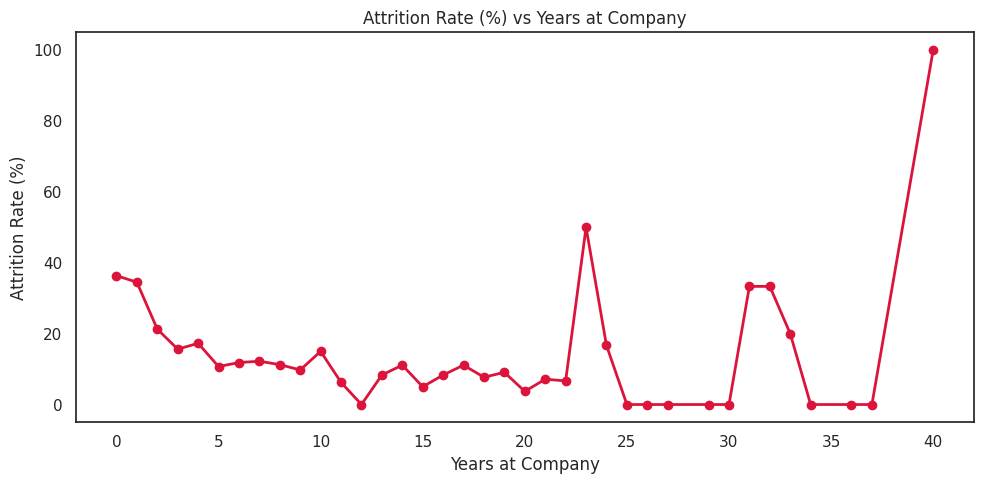

In [ ]:
plt.figure(figsize=(10, 5))
tenure_attr = df_hr.groupby('YearsAtCompany')['Attrition_Num'].mean() * 100
plt.plot(tenure_attr.index, tenure_attr.values, marker='o', color='crimson', linewidth=2)
plt.title('Attrition Rate (%) vs Years at Company')
plt.xlabel('Years at Company')
plt.ylabel('Attrition Rate (%)')
plt.tight_layout()
plt.show()

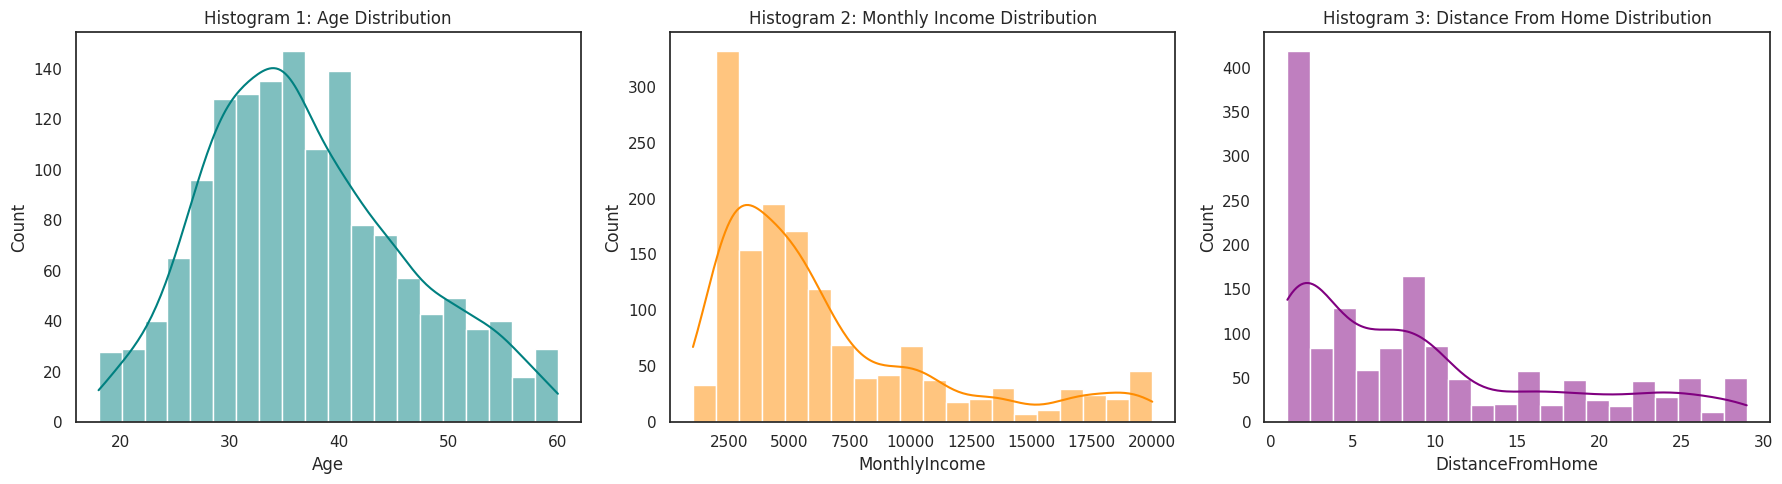

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram 1: Age
sns.histplot(df_hr['Age'], bins=20, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Histogram 1: Age Distribution')

# Histogram 2: Monthly Income
sns.histplot(df_hr['MonthlyIncome'], bins=20, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Histogram 2: Monthly Income Distribution')

# Histogram 3: Distance From Home
sns.histplot(df_hr['DistanceFromHome'], bins=20, kde=True, ax=axes[2], color='purple')
axes[2].set_title('Histogram 3: Distance From Home Distribution')

plt.tight_layout()
plt.show()

/tmp/ipykernel_783/195934791.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y='MonthlyIncome', data=df_hr, ax=axes[0], palette='Set2')
/tmp/ipykernel_783/195934791.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y='Age', data=df_hr, ax=axes[1], palette='Set2')
/tmp/ipykernel_783/195934791.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y='DistanceFromHome', data=df_hr, ax=axes[2], palette='Set2')


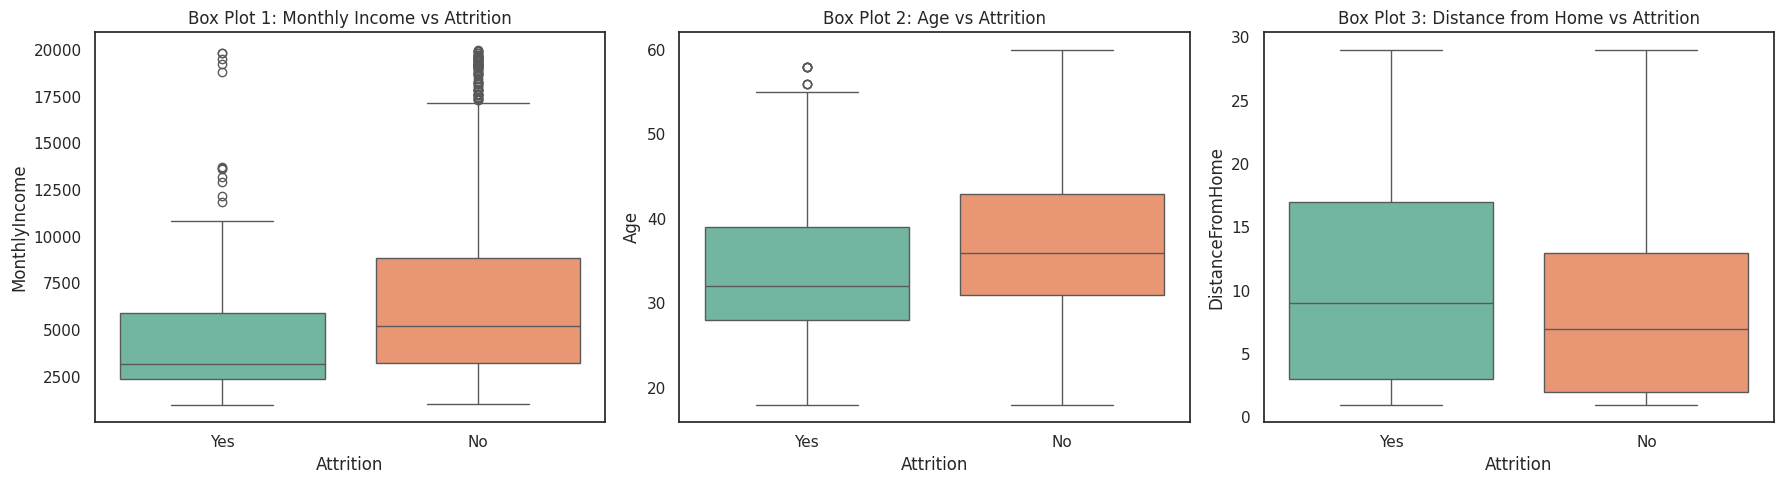

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box Plot 1: Monthly Income vs Attrition
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df_hr, ax=axes[0], palette='Set2')
axes[0].set_title('Box Plot 1: Monthly Income vs Attrition')

# Box Plot 2: Age vs Attrition
sns.boxplot(x='Attrition', y='Age', data=df_hr, ax=axes[1], palette='Set2')
axes[1].set_title('Box Plot 2: Age vs Attrition')

# Box Plot 3: Distance from Home vs Attrition
sns.boxplot(x='Attrition', y='DistanceFromHome', data=df_hr, ax=axes[2], palette='Set2')
axes[2].set_title('Box Plot 3: Distance from Home vs Attrition')

plt.tight_layout()
plt.show()

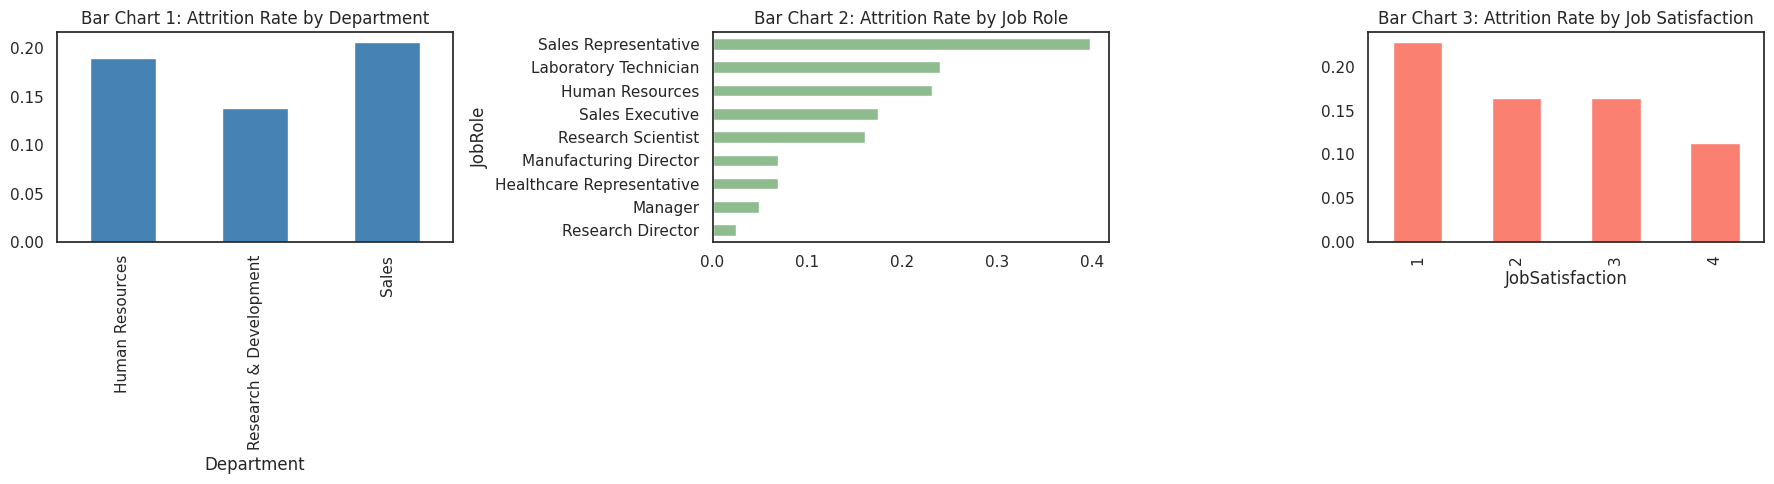

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Bar Chart 1: Attrition Rate by Department
df_hr.groupby('Department')['Attrition_Num'].mean().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Bar Chart 1: Attrition Rate by Department')

# Bar Chart 2: Attrition Rate by Job Role
df_hr.groupby('JobRole')['Attrition_Num'].mean().sort_values().plot(kind='barh', ax=axes[1], color='darkseagreen')
axes[1].set_title('Bar Chart 2: Attrition Rate by Job Role')

# Bar Chart 3: Attrition Rate by Job Satisfaction
df_hr.groupby('JobSatisfaction')['Attrition_Num'].mean().plot(kind='bar', ax=axes[2], color='salmon')
axes[2].set_title('Bar Chart 3: Attrition Rate by Job Satisfaction')
plt.tight_layout()
plt.show()

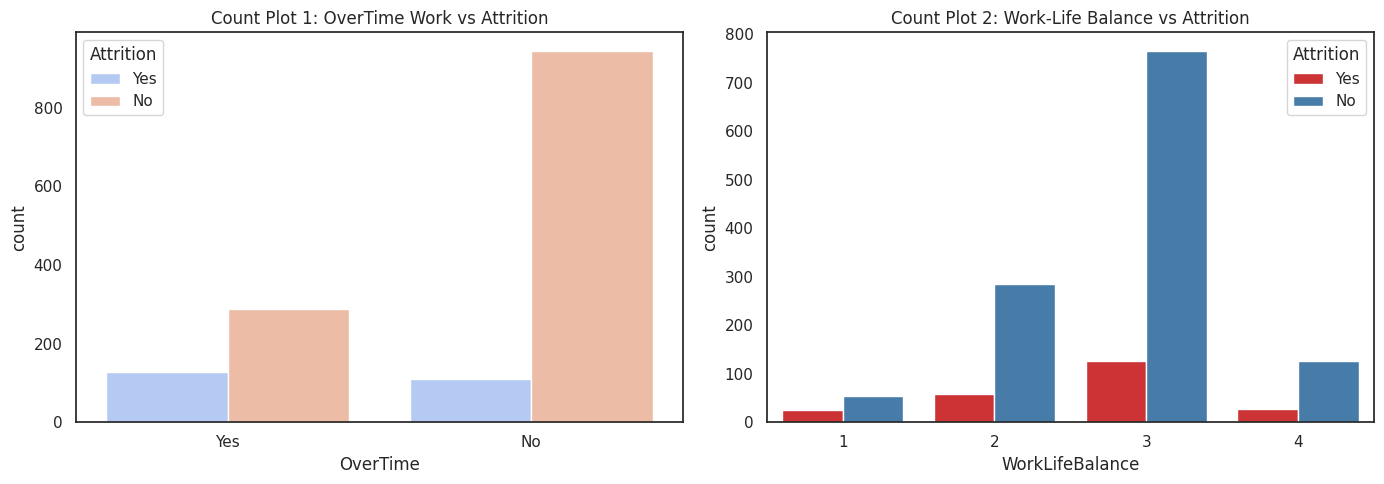

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count Plot 1: OverTime vs Attrition
sns.countplot(x='OverTime', hue='Attrition', data=df_hr, ax=axes[0], palette='coolwarm')
axes[0].set_title('Count Plot 1: OverTime Work vs Attrition')

# Count Plot 2: Work-Life Balance vs Attrition
sns.countplot(x='WorkLifeBalance', hue='Attrition', data=df_hr, ax=axes[1], palette='Set1')
axes[1].set_title('Count Plot 2: Work-Life Balance vs Attrition')

plt.tight_layout()
plt.show()

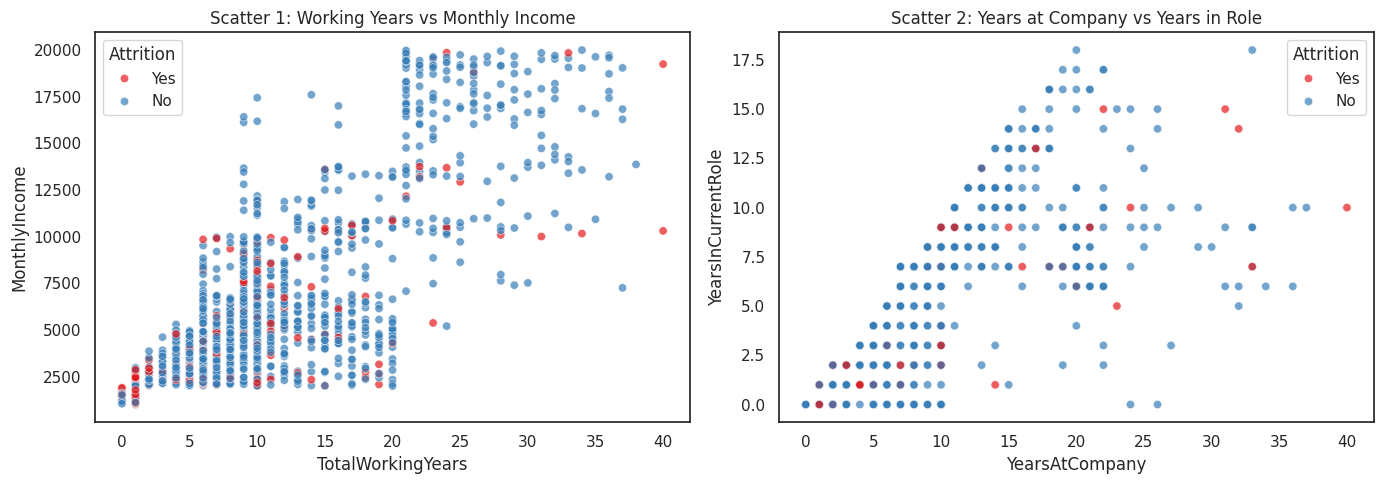

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter Plot 1: Working Years vs Monthly Income
sns.scatterplot(x='TotalWorkingYears', y='MonthlyIncome', hue='Attrition', data=df_hr, alpha=0.7, ax=axes[0], palette='Set1')
axes[0].set_title('Scatter 1: Working Years vs Monthly Income')

# Scatter Plot 2: Years at Company vs Years in Role
sns.scatterplot(x='YearsAtCompany', y='YearsInCurrentRole', hue='Attrition', data=df_hr, alpha=0.7, ax=axes[1], palette='Set1')
axes[1].set_title('Scatter 2: Years at Company vs Years in Role')

plt.tight_layout()
plt.show()

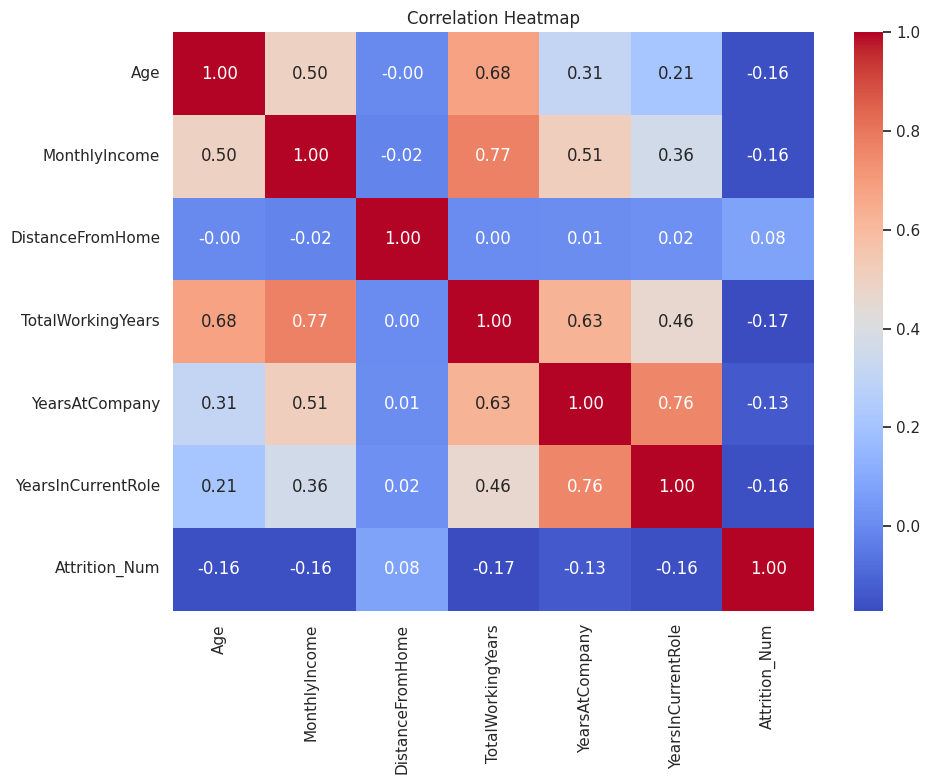

In [ ]:
plt.figure(figsize=(10, 8))
cols = ['Age', 'MonthlyIncome', 'DistanceFromHome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'Attrition_Num']
sns.heatmap(df_hr[cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

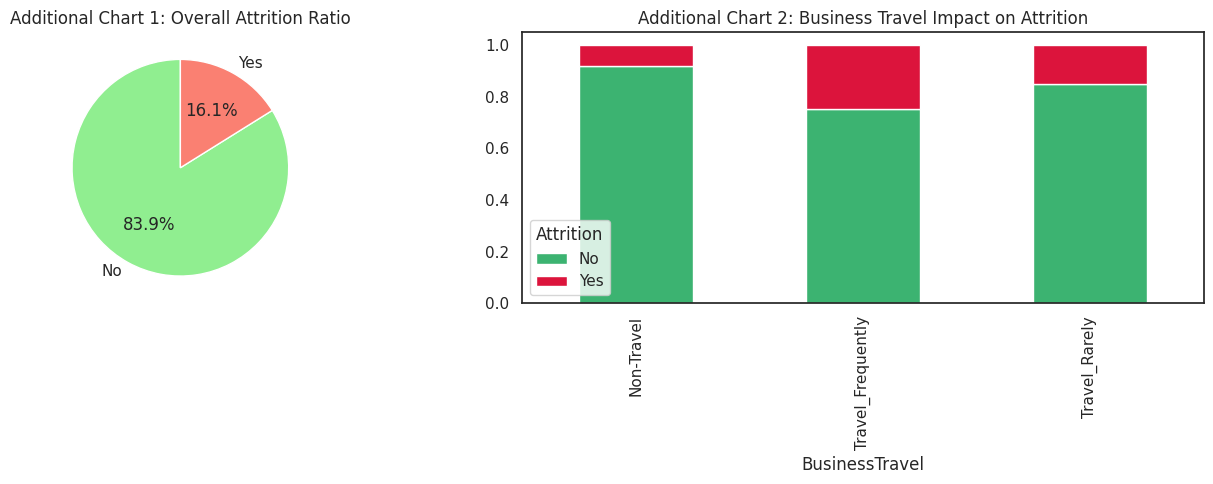

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Additional Chart 1: Pie Chart (Overall Attrition)
df_hr['Attrition'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightgreen', 'salmon'], ax=axes[0], startangle=90)
axes[0].set_title('Additional Chart 1: Overall Attrition Ratio')
axes[0].set_ylabel('')

# Additional Chart 2: Stacked Bar (Business Travel vs Attrition)
travel_att = pd.crosstab(df_hr['BusinessTravel'], df_hr['Attrition'], normalize='index')
travel_att.plot(kind='bar', stacked=True, color=['mediumseagreen', 'crimson'], ax=axes[1])
axes[1].set_title('Additional Chart 2: Business Travel Impact on Attrition')

plt.tight_layout()
plt.show()